I will be creating a model to predict whether a patient that is in the ICU will develop sepsis or not using the dataset from Physionet which gave over 40,000 total patients and whether they developed sepsis. Each patient has one row per hour that they stayed in the ICU; the goal of each row is to show their vitals/labs at that hour.

In [83]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

Now I will be reading in the data that I downloaded into two PSV files, there was training set A and training set B

In [13]:
import glob #grabs each file path that matches a pattern
import os #gets the patient id from each file name we are at

patientsA = [] #stores each patient df
for patient in glob.glob(r'C://training//training_setA/*.psv'):
    df = pd.read_csv(patient, delimiter='|') #stores current patient as a df
    df['patient_id'] = os.path.basename(patient)[:-4] #saves the id part from the path for the patient id column
    patientsA.append(df) #store in the array
dfA = pd.concat(patientsA, ignore_index=True) #creates our set A df using all of the patients

#now for set B
patientsB = []
for patient in glob.glob(r'C://training//training_setB/*.psv'):
    df = pd.read_csv(patient, delimiter='|')
    df['patient_id'] = os.path.basename(patient)[:-4]
    patientsB.append(df)
dfB = pd.concat(patientsB, ignore_index=True)

Now combining each set into one dataframe and then saving it so we don't need to load the data each time

In [2]:
df = pd.concat([dfA,dfB], ignore_index=True)
df.to_pickle('sepsis_df')

NameError: name 'dfA' is not defined

Now going to get some of the stats about the dataset

In [2]:
df = pd.read_pickle('sepsis_df')
#adding a Farenheit column for the temperature so it is easier for me to read
df['tempF'] = (df['Temp']*(9/5)) + 32
shape = df.shape #shape of the data
sepsis_percent = len(df[df['SepsisLabel']==1]) / len(df) #percentage of rows that actually had sepsis
#info = df.info()
#describe = df.describe()
num_patients = len(df.groupby('patient_id')) #there are 40,336 patients here
stay_len = df.groupby('patient_id')['ICULOS'].max() #gets the last hour of each patients ICU stay-- that col is holding the current number of hours the patient has been in the ICU
stay_len.describe() #shows the stats about the general patient length of stay in the ICU in hours

count    40336.000000
mean        39.010115
std         22.924641
min          8.000000
25%         24.000000
50%         39.000000
75%         47.000000
max        336.000000
Name: ICULOS, dtype: float64

Now splitting the data by patient (keeping whole patient records together) and stratify on the proporiton of patients that have had sepsis

In [3]:
patients = df.groupby('patient_id')['SepsisLabel'].max() #each patient will hold max of SepsisLabel, since its binary it will either by 1 if they got it or 0 if not
patients_train, patients_test = train_test_split(patients, test_size=0.2, stratify=patients, random_state=445)
#checking to see if the sepsis positives were distributed evenly
perc1 = sum(patients_train==1) / len(patients_train)
perc2 = sum(patients_test==1) / len(patients_test)

Building the dataframes back up using the patients that fell into both

In [5]:
train_df = df[df['patient_id'].isin(patients_train.index)]
test_df = df[df['patient_id'].isin(patients_test.index)]
p1 = sum(train_df['SepsisLabel']==1) / len(train_df)
p2 = sum(test_df['SepsisLabel']==1) / len(test_df)
p1

0.0180131431350143

Now I'm going to perform EDA on the training set to get insights as to which features are going to matter the most along with the data quality and the structure. Specifically, I'll end up checkin how the vitals bevave before turning positive

In [6]:
X = train_df.copy()
X.head()

,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,patient_id,tempF
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,1,0,p000001,NaN
1,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,2,0,p000001,NaN
2,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,3,0,p000001,NaN
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,4,0,p000001,NaN
4,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,NaN,NaN,...,NaN,83.14,0,NaN,NaN,-0.03,5,0,p000001,NaN


In [7]:
#getting the data quality-- the amount of missing values and how inconsistent the data is 
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1240039 entries, 0 to 1552174
Data columns (total 43 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   HR                1117657 non-null  float64
 1   O2Sat             1078839 non-null  float64
 2   Temp              419814 non-null   float64
 3   SBP               1059828 non-null  float64
 4   MAP               1085945 non-null  float64
 5   DBP               851985 non-null   float64
 6   Resp              1050027 non-null  float64
 7   EtCO2             45954 non-null    float64
 8   BaseExcess        66626 non-null    float64
 9   HCO3              51787 non-null    float64
 10  FiO2              102878 non-null   float64
 11  pH                85414 non-null    float64
 12  PaCO2             68560 non-null    float64
 13  SaO2              42605 non-null    float64
 14  AST               20150 non-null    float64
 15  BUN               85161 non-null    float64
 16  Alkal

Getting the percentage of NaN values per feature and then the percentage of NaN values for rows that are positive in Sepsis

In [8]:
feature_nan = X.isna().mean().sort_values(ascending=False)
feature_nan_positive = X[X['SepsisLabel']==1].isna().mean().sort_values(ascending=False)
feature_nan

Bilirubin_direct    0.998051
Fibrinogen          0.993358
TroponinI           0.990443
Bilirubin_total     0.985068
Alkalinephos        0.983921
AST                 0.983751
Lactate             0.973316
PTT                 0.970625
SaO2                0.965642
EtCO2               0.962941
Phosphate           0.959790
HCO3                0.958238
Chloride            0.954716
BaseExcess          0.946271
PaCO2               0.944711
Calcium             0.940914
Platelets           0.940587
Creatinine          0.938997
Magnesium           0.936982
WBC                 0.935905
BUN                 0.931324
pH                  0.931120
Hgb                 0.926177
FiO2                0.917036
Hct                 0.911447
Potassium           0.906937
Glucose             0.829122
tempF               0.661451
Temp                0.661451
Unit1               0.393662
Unit2               0.393662
DBP                 0.312937
Resp                0.153231
SBP                 0.145327
O2Sat         

Getting the value ranges to check for impossible values so I can mark those as NaN

In [9]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
HR,1117657.0,84.600856,17.332981,20.00,72.00,83.50,96.00,280.00
O2Sat,1078839.0,97.199200,2.946072,20.00,96.00,98.00,99.50,100.00
Temp,419814.0,36.979968,0.771570,20.90,36.50,37.00,37.50,50.00
SBP,1059828.0,123.759675,23.200454,20.00,107.00,121.00,138.00,300.00
MAP,1085945.0,82.402611,16.336573,20.00,71.00,80.00,92.00,300.00
DBP,851985.0,63.838317,13.983882,20.00,54.00,62.00,72.00,300.00
Resp,1050027.0,18.717314,5.092496,1.00,15.00,18.00,21.50,100.00
EtCO2,45954.0,32.764743,7.973384,10.00,28.00,33.00,38.00,100.00
BaseExcess,66626.0,-0.694092,4.276866,-32.00,-3.00,0.00,1.00,100.00
HCO3,51787.0,24.072225,4.380849,0.00,22.00,24.00,26.50,55.00


In [10]:
breath_per_min = X[(X['Resp'] < 10)]['SepsisLabel'].value_counts()
base_high_excess = X[X['BaseExcess'] > -20]['SepsisLabel'].value_counts()
hc03 = X[X['HCO3'] > 35]['SepsisLabel'].value_counts()
fio2 = X[X['FiO2'] > 0.3]['SepsisLabel']
ph = X[X['pH'] < 7.35]['SepsisLabel'].value_counts()
ast = X[X['AST'] > 9000]['SepsisLabel'].value_counts()
bun = X[X['BUN'] > 100]['SepsisLabel'].value_counts()
alkalinephos = X[X['Alkalinephos'] > 150]['SepsisLabel'].value_counts()
calcium = X[X['Calcium'] < 7]['SepsisLabel'].value_counts()
chloride = X[X['Chloride'] > 110]['SepsisLabel'].value_counts()
creatinine = X[X['Creatinine'] > 3]['SepsisLabel'].value_counts()
bilirubin = X[X['Bilirubin_direct'] > 0.3]['SepsisLabel'].value_counts()
bilirubin_total = X[X['Bilirubin_total'] > 1.3]['SepsisLabel'].value_counts()
glucose = X[X['Glucose'] > 170]['SepsisLabel'].value_counts()
lactate = X[X['Lactate'] > 3]['SepsisLabel'].value_counts()
wbc = X[X['WBC'] > 12]['SepsisLabel'].value_counts()
platalets = X[X['Platelets'] < 90]['SepsisLabel'].value_counts()


In [11]:
#each patient results, either 0 or 1 for sepsis
patient_result = X.groupby('patient_id')['SepsisLabel'].max()


Now I am going to create an "hours till sepsis" feature to track how certain vitals and labs change as we get closer to the first hour a patient was classified to have sepsis. A patient does not get the sepsis label until 6 hours before they get it officially, for reference. I will get the first ICULOS(hour in the ICU) that a patient was classified with sepsis and then subtract each ICULOS by that to get the hours away.

In [12]:
hour_diagnosed = X[X['SepsisLabel'] == 1].groupby('patient_id')['ICULOS'].min() + 6 #this is the first hour that the patient actually had sepsis, it's 6 hours after they are labeled to have it
#now give an onset marker column to hold the hour of onset for each patient 
X['onset'] = X['patient_id'].map(hour_diagnosed) #it only maps a number to the patients with an id labeled in the hour diagnosed df
#now the hours till sepsis column to show the number of hours till they hit that onset marker-- it's current hour in ICU (ICULOS) - onset so it'll be negative before we hit onset
X['hours_till_onset'] = X['ICULOS'] - X['onset']

Next I will use that onset column to get the average vital sign at each hour before onset. So we are grouping by the hour till onset column and then going to make a plot of the average vital compared to that avg vital per hour before onset and see how it moves leading up to onset to see if we can find any correlations

In [176]:
vitals = ["HR","tempF", "SBP", "Resp",'DBP','WBC'] #using these vitals because they are the most important ones
#only grabbing the vitals from 36 hours before onset to 6 hours after onset, so first need to make a df of the eligible rows
hour_window = X[(X['hours_till_onset'].between(-36,6))]
#now get the avg vitals using these rows 
avg_vitals_hourly = hour_window.groupby('hours_till_onset')[vitals].mean() #df to hold the avg of each vital from 24 hours before onset to 6 hours after
#now get the average of each vital in each patient
avg_vitals = X[X['hours_till_onset'].isna()][vitals].mean() #for non septic patients
avg_vitals_hourly
avg_vitals

HR        84.132533
tempF     98.532377
SBP      123.728123
Resp      18.578909
DBP       63.979819
WBC       11.288865
dtype: float64

Now creating a plot of the averages from 36 hours before onset to 6 hours after onset

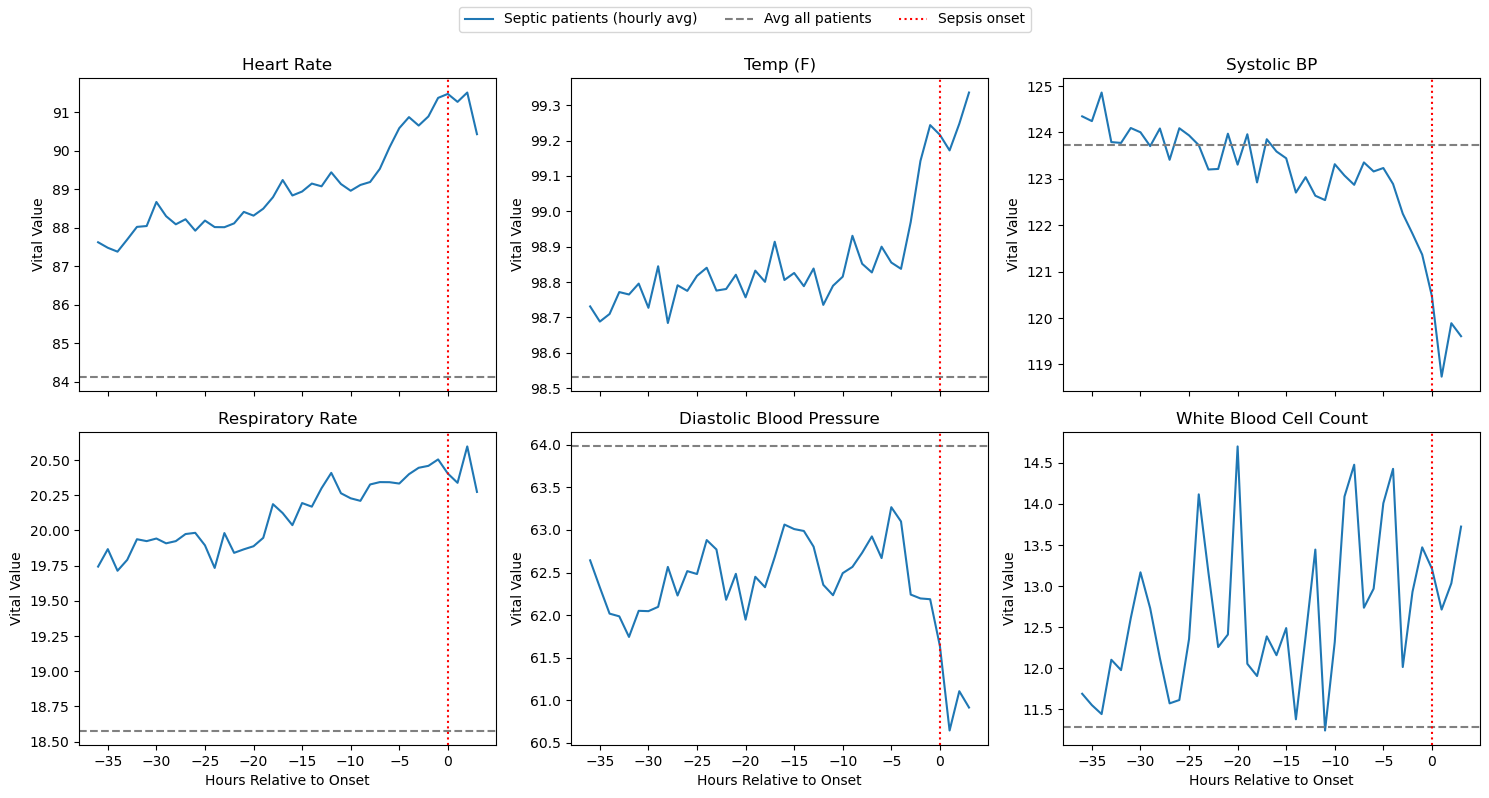

In [177]:
vital_names = {'HR': 'Heart Rate', 'tempF': 'Temp (F)',
               'SBP': 'Systolic BP', 'Resp': 'Respiratory Rate', 'DBP': 'Diastolic Blood Pressure','WBC':"White Blood Cell Count"}

#each vital gets its own subplot since they're on very different scales
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for ax, vital in zip(axes.flat, vitals):
    ax.plot(avg_vitals_hourly.index, avg_vitals_hourly[vital], color='tab:blue', label='Septic patients (hourly avg)')
    ax.axhline(y=avg_vitals[vital], color='gray', linestyle='--', label='Avg all patients')
    ax.axvline(x=0, color='red', linestyle=':', label='Sepsis onset')
    ax.set_title(vital_names[vital])
    ax.set_ylabel('Vital Value')

for ax in axes[1]:
    ax.set_xlabel('Hours Relative to Onset')

#one shared legend for the whole figure
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

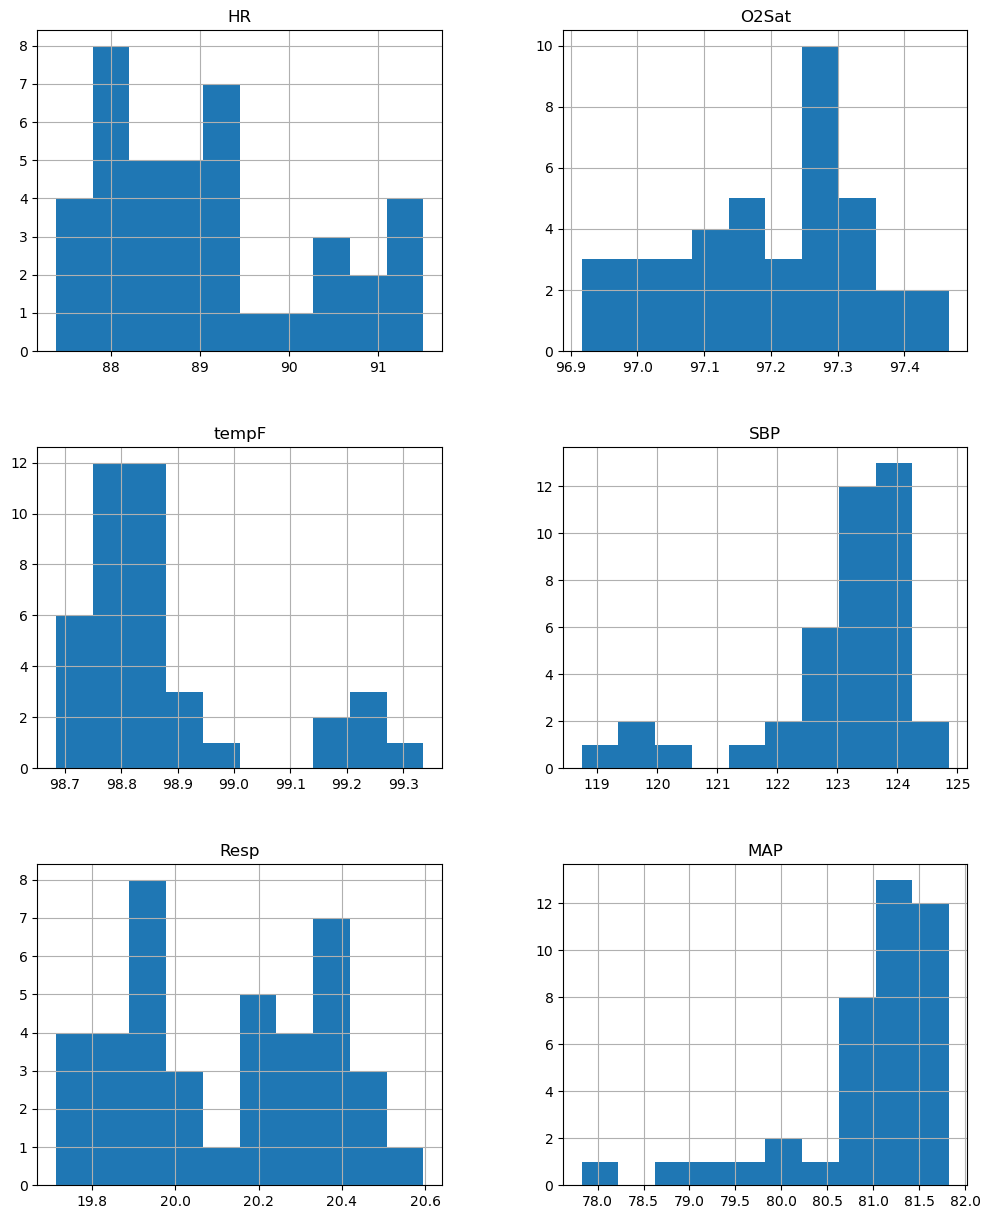

In [15]:
avg_vitals_hourly.hist(figsize=(12,15))
plt.show()

In [16]:
avg_icu_stay_sepsis = X[X['hours_till_onset'].notna()]['ICULOS'].median()
avg_icu_stay_non_sepsis = X[X['hours_till_onset'].isna()]['ICULOS'].median()
avg_icu_stay_sepsis #42 hours median length of stay in the icu
avg_icu_stay_non_sepsis #22 hours median length of stay in the icu

20.0

In [162]:
lactate_hour_distributed = X[(X['SepsisLabel']==1)&(X['Lactate'].notna())].groupby('patient_id')['hours_till_onset'].min()
lactate_hour_distributed.value_counts()

hours_till_onset
-6.0    114
-3.0    112
 0.0    106
-5.0    103
-4.0     93
-1.0     80
 1.0     76
-2.0     60
 2.0     44
 3.0     19
Name: count, dtype: int64

In [173]:
X[(X['Lactate'].notna())].groupby('patient_id')['ICULOS'].min().value_counts()

ICULOS
2      2108
3      1422
4      1036
5       747
6       607
       ... 
101       1
116       1
81        1
86        1
145       1
Name: count, Length: 122, dtype: int64

Looking at the cell below, it shows that on average the labs were recorded around 2 times per day

In [17]:
labs = ["Lactate", "WBC", "Creatinine", "Platelets", "BUN", "Glucose"]  # add any you want

per_patient = X.groupby("patient_id").agg(
    {**{lab: lambda s: s.notna().sum() for lab in labs}, "ICULOS": "max"})

per_day = per_patient[labs].div(per_patient["ICULOS"], axis=0) * 24
per_day.median()

Lactate       0.000000
WBC           1.263158
Creatinine    1.297297
Platelets     1.263158
BUN           1.333333
Glucose       2.790698
dtype: float64

Now I'm going to create a cleaning function to use on the dataframe based on my findings from eda. The idea is going to be to get rid of impossible values (like a 400 bpm heart rate) and then drop some of the columns that are missing over 99% of the time

In [18]:
def clean_df(df):
    #need to create copy so we dont mess with original df and then add farenheith column for temp
    df = df.copy()
    if 'Temp' in df.columns:
        df["tempF"] = df["Temp"] * 9/5 + 32

    dropping = ['Bilirubin_direct','Fibrinogen','TroponinI','Temp']
    df = df.drop(columns=dropping, errors='ignore') #ignore errors in case those cols not there
    
    cols = df.columns #list of the columns in my df currently, using to check before editing to avoid errors

    #this holds the ranges I am going to allow, going to iterate over this to edit 
    feature_ranges = {'HR':(20,300),'O2Sat':(50,100),'tempF':(80,110),'SBP':(20,300),'FiO2':(0.21,1.0)}
    #looping over the features in the dict above, if not in range it is set to NaN
    for feature, (low,high) in feature_ranges.items():
        if feature in cols: #checking so we dont error out
            df[feature] = df[feature].where(df[feature].between(low,high)) #replaces outliers with NaN
        else:
            print(f'Warning: {feature} not in the dataframe, so skipping')
    #finally need to sort the df based on the patient id and the ICULOS so when we add the temporal features they are in correct order
    df = df.sort_values(by=['patient_id','ICULOS'])
    return df

Now I will be using the cleaning function I created to get some predictions using a dummy model to predict the probability of each class using "prior" strategy (this just gives the proportion of each class in the training labels and uses those to make predictions). Then I will get a baseline ROC AUC using the positive class probability as the thresholds so we can then compare the ROC AUC curve/score for our future models

In [32]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold

In [42]:
df = clean_df(X)
y = df['SepsisLabel']
df = df.drop(columns=['hours_till_onset','onset','SepsisLabel'])

In [ ]:
dummy = DummyClassifier(strategy='prior', random_state=42) #create the dummy classifier-- it will give each row a probability of the sepsis (class=1) proportion in the dataset-- around 1.8% of being positive
dummy.fit(df,y)
dummy.class_prior_ #shows the probability of being in each class, first is negative and 2nd is positive

array([0.98198686, 0.01801314])

In [ ]:
#now get the prediction probabilites-- all will be 0.018 because that was the positive class proportion and then use each predicted probability as a threshold to get the ROC AUC-- should get pt (1,1) because TPR will be 1 since we find 
#all positives and FPR will be 1 since we say everything is positive
predicted_probs = dummy.predict_proba(df)
predicted_probs #need to grab the 2nd item in each because that is the probability of being positive 

array([[0.98198686, 0.01801314],
       [0.98198686, 0.01801314],
       [0.98198686, 0.01801314],
       ...,
       [0.98198686, 0.01801314],
       [0.98198686, 0.01801314],
       [0.98198686, 0.01801314]], shape=(1240039, 2))

Here we can see our ROC AUC is 0.5 due to random guessing because we used the lowest probability as the threshold so everything was predicted to be positive. This means that we found every positive so the sensitivity was 1 but
#we also labeled each negative as positive so our FPR was also 1. Therfore it creates a diagonal line from (0,0) to (1,1) which is why the AUC is 0.5; this is our baseline ROC AUC

In [ ]:
auc_score = roc_auc_score(y, predicted_probs[:,1])
auc_score 

0.5

Now getting the ROC Curve

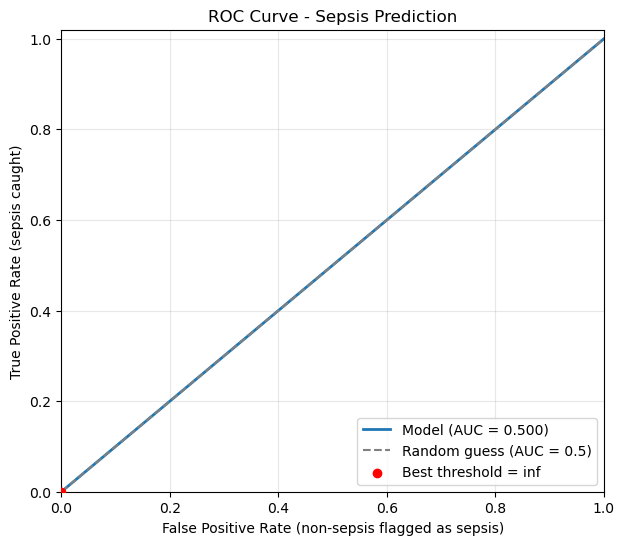

In [65]:
fpr, tpr, thresholds = roc_curve(y_true=y, y_score=predicted_probs[:,1])
from sklearn.metrics import auc

roc_auc = auc(fpr, tpr)  # area under the curve

# best balance of catching sepsis vs. false alarms (Youden's J = tpr - fpr)
best_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[best_idx]

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'Model (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)')
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', zorder=5,
            label=f'Best threshold = {best_threshold:.3f}')

plt.xlabel('False Positive Rate (non-sepsis flagged as sepsis)')
plt.ylabel('True Positive Rate (sepsis caught)')
plt.title('ROC Curve - Sepsis Prediction')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

Now I am going to use the SIRS criteria which is a quick meausre to indicate whether someone might have sepsis based on their vitals. It includes temperature<96.8 or T>100.4, heart rate < 90bpm, respiratory rate > 20 breaths per min, and white blood cell count > 12,000 or less than 4000. I am going to get each patients score using this criteria (0-4) and then get a ROC AUC using each score as a threshold for prediction. For example, if someone has all 4 checked than that threshold will be 4 and each patient who has score 4 will be positive while the rest will be negative (class=0). Then it will check to see how they compared to the true labels and get the TPR and FPR and put its point on the ROC curve. In the end we will use this ROC AUC as another baseline for predictions, if our model is not doing at least as good as this than it is not working

In [ ]:
sirs_scores = ((df['tempF']>100.4) | (df['tempF'] < 96.8)).astype(int) + (df['HR'] > 90).astype(int) + (df['Resp'] > 20).astype(int) + ((df['WBC'] > 12) | (df['WBC'] < 4)).astype(int)
sirs_scores.value_counts() #most are 0 (least likely) and it goes down from there in each bucket

0    643570
1    415722
2    164918
3     15419
4       410
Name: count, dtype: int64

In [ ]:
#now putting the scores into the ROC AUC function to get an AUC score using each score as a proability 
auc_score_sirs = roc_auc_score(y, sirs_scores)
auc_score_sirs #we got .61 which is slightly better than random guessing 

0.6083117388555582

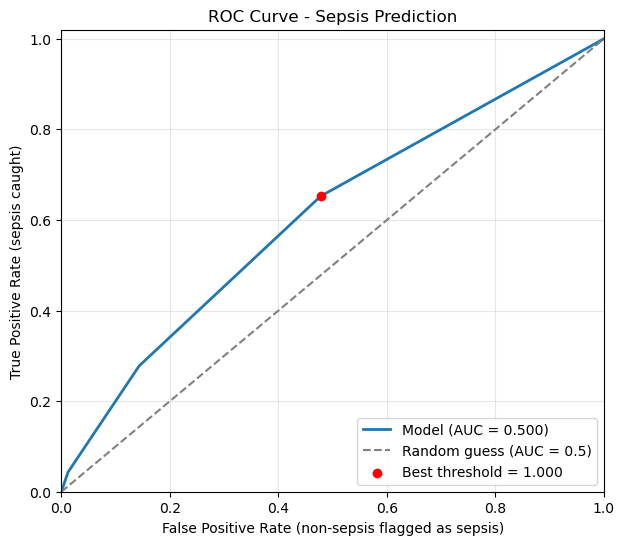

In [77]:
fpr, tpr, thresholds = roc_curve(y, sirs_scores)
# best balance of catching sepsis vs. false alarms (Youden's J = tpr - fpr)
best_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[best_idx]

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'Model (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)')
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', zorder=5,
            label=f'Best threshold = {best_threshold:.3f}')

plt.xlabel('False Positive Rate (non-sepsis flagged as sepsis)')
plt.ylabel('True Positive Rate (sepsis caught)')
plt.title('ROC Curve - Sepsis Prediction')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

So the standard clinical SIRS evaludation got a 61% AUC, can machine learning beat it? (Domain baseline)
Now I will get a logistic regression model using only the features I have up to this point for another baseline (the bare model baseline)

In [86]:
#first need to make the pre-processing transformer 
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import FunctionTransformer


log_reg = make_pipeline(
    FunctionTransformer(lambda df: df.drop(columns=['patient_id'], errors='ignore')),
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LogisticRegression(random_state=42, max_iter=1000) #raising the iteration to 1000 so it has more GD to find the parameters for each feature
)
cv = StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True) #specified 5 fold CV
groups = df['patient_id'] #grouping by patient id 
predicted_prob_log_reg = cross_val_predict(log_reg, df, y, groups=groups, cv=cv, n_jobs=-1, method='predict_proba')

Now getting the ROC AUC for the logistic regression predictions

In [ ]:
log_reg_auc = roc_auc_score(y, predicted_prob_log_reg[:,1])
log_reg_auc #got 71% AUC score 

0.7132396267047483

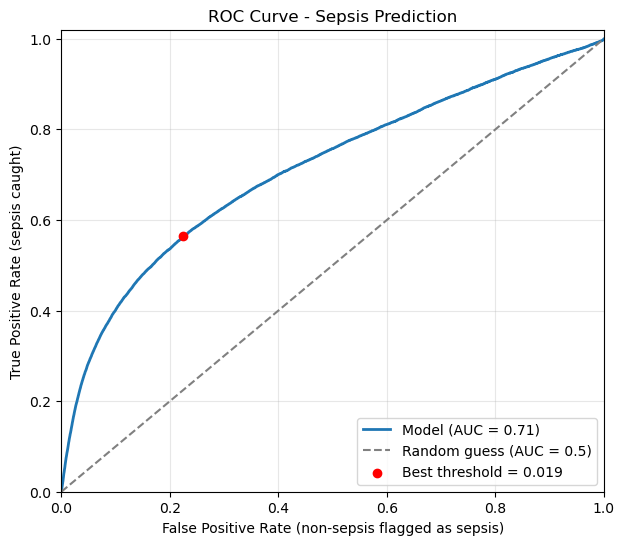

In [91]:
fpr, tpr, thresholds = roc_curve(y, predicted_prob_log_reg[:,1])
best_idx = np.argmax(tpr - fpr)
best_threshold = thresholds[best_idx]

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'Model (AUC = {round(log_reg_auc,2)})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.5)')
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', zorder=5,
            label=f'Best threshold = {best_threshold:.3f}')

plt.xlabel('False Positive Rate (non-sepsis flagged as sepsis)')
plt.ylabel('True Positive Rate (sepsis caught)')
plt.title('ROC Curve - Sepsis Prediction')
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

In [112]:
from sklearn.metrics import average_precision_score, precision_recall_curve


pr_score = average_precision_score(y, predicted_prob_log_reg[:,1]) #gives us the score for how the precision holds up at each threshold, its the avg precision from all the thresholds
prec,recall,thresholds = precision_recall_curve(y, predicted_prob_log_reg[:,1])


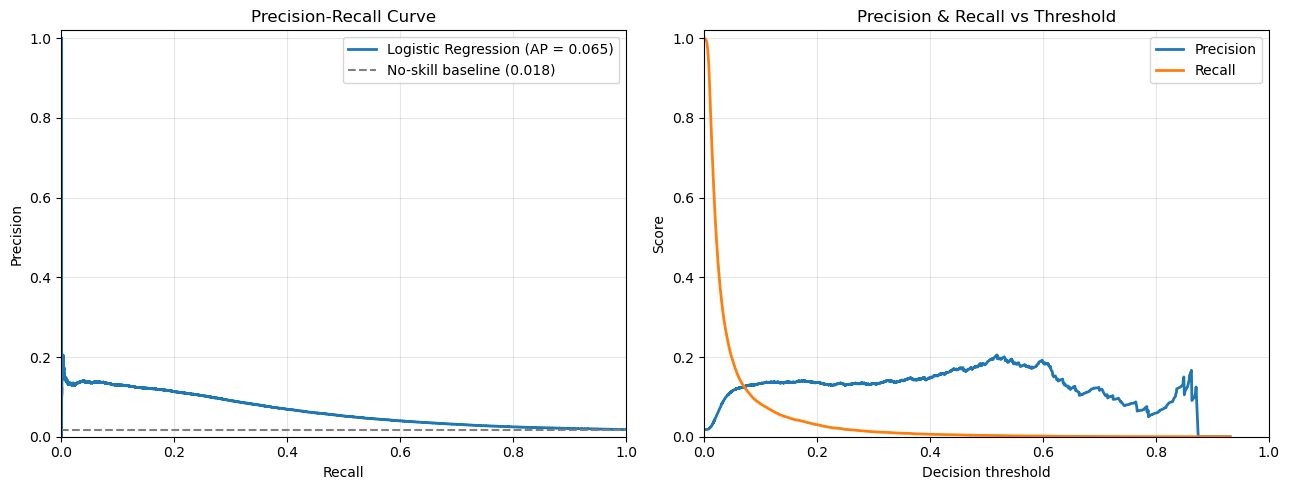

In [97]:
baseline = y.mean()  # share of positives; a random model scores this

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1) Precision-Recall curve
axes[0].plot(recall, prec, lw=2, label=f"Logistic Regression (AP = {pr_score:.3f})")
axes[0].axhline(baseline, color="gray", ls="--", label=f"No-skill baseline ({baseline:.3f})")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_title("Precision-Recall Curve")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.02)
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2) Precision & Recall vs threshold
# (prec/recall have one more element than thresholds, so drop the last one)
axes[1].plot(thresholds, prec[:-1], lw=2, label="Precision")
axes[1].plot(thresholds, recall[:-1], lw=2, label="Recall")
axes[1].set_xlabel("Decision threshold")
axes[1].set_ylabel("Score")
axes[1].set_title("Precision & Recall vs Threshold")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#let me get the precision when we use 80% recall:
valid_recall = recall[:-1] >= 0.8
indices = np.where(valid_recall)[0][-1] #gets the last index of the recall at or above 0.8 to use in precision and threshold
thresholds[indices], recall[indices], prec[indices] #only actually positive when we say it is 2.4% of the time using our threshold of 0.012 to get a recall of 80%

(np.float64(0.01216753970059537),
 np.float64(0.8000179075077226),
 np.float64(0.024690027550036336))

Now that we have our baselines (the dummy that predicts the proportion of positive in the training data for everything, the SIRS score thresholds, and logistic regression) for the ROC AUC and precision/recall lets see if we can improve that using temporal features (recent history)

In [126]:
df.isna().mean().sort_values(ascending=True)

ICULOS             0.000000
HospAdmTime        0.000000
Gender             0.000000
Age                0.000000
patient_id         0.000000
HR                 0.098692
MAP                0.124265
O2Sat              0.130176
SBP                0.145327
Resp               0.153231
DBP                0.312937
Unit2              0.393662
Unit1              0.393662
tempF              0.661457
Glucose            0.829122
Potassium          0.906937
Hct                0.911447
FiO2               0.917277
Hgb                0.926177
pH                 0.931120
BUN                0.931324
WBC                0.935905
Magnesium          0.936982
Creatinine         0.938997
Platelets          0.940587
Calcium            0.940914
PaCO2              0.944711
BaseExcess         0.946271
Chloride           0.954716
HCO3               0.958238
Phosphate          0.959790
EtCO2              0.962941
SaO2               0.965642
PTT                0.970625
Lactate            0.973316
AST                0

In [186]:
df.head()

,HR,O2Sat,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,FiO2,...,WBC,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,patient_id,tempF
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,p000001,NaN
1,97.0,95.0,98.0,75.33,NaN,19.0,NaN,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,p000001,NaN
2,89.0,99.0,122.0,86.00,NaN,22.0,NaN,NaN,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,p000001,NaN
3,90.0,95.0,NaN,NaN,NaN,30.0,NaN,24.0,NaN,NaN,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,p000001,NaN
4,103.0,88.5,122.0,91.33,NaN,24.5,NaN,NaN,NaN,0.28,...,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,p000001,NaN


Going to first work on the "hours since lab" feature to get a read on how many hours it has been since the patient was ordered an important lab

In [211]:
#generalizing it to each lab I chose
labs = ['Lactate','WBC','Creatinine','Platelets','Bilirubin_total','pH']
#for each one we need to make temprorary helper series to hold the hour it was drawn and then ffill to get hour of last draw 
#the real columns will be the difference between curr hour and the hour of last draw
for lab in labs:
    hour_helper = df['ICULOS'].where(df[lab].notna()) #holds the hour a new one is ordered
    last_hour = hour_helper.groupby(df['patient_id']).ffill()
    df[f'hours_since_{lab.lower()}'] = df['ICULOS'] - last_hour

In [ ]:
#now store those last measured values as the current values in those labs if NaN
for lab in labs:
    df[lab] = df[lab].groupby(df['patient_id']).ffill() #just forward fills the last non NaN value so we can look at the current value and last hour it was taken

In [250]:
#now going to get the rate of lactate draws-- (#draws to now)/(ICULOS) it shows how many per hour you've been here
#hours_since_lactate is 0 exactly on the hours a new lactate was drawn (NaN before the first draw, which counts as not drawn)
helper_drawn = (df['hours_since_lactate'] == 0).astype(int) #1 if drawn this hour, 0 if not
df['lactate_count'] = helper_drawn.groupby(df['patient_id']).cumsum() #running total of draws so far for each patient
df['lactate_rate_per_hour'] = round(df['lactate_count'] / df['ICULOS'],2) #draws per hour in the ICU so far (ICULOS starts at 1 so no divide by 0)